# Muse Spark Open vs DeepSeek V4.1 Flash — short-answer demo

Meta-event friendly head-to-head on **UiPad-style answer types**, text-only (no screenshots, **no coordinates**).

| Answer type | Bench |
|---|---|
| number | GSM8K |
| yes/no | BoolQ |
| string | NQ-Open |
| choice | ARC-Easy |

Pipeline: Fireworks serverless → deterministic grade → pass@1 charts.

**Live mode:** `RUN_SWEEP = True` — re-runs Fireworks (resumable into `results.jsonl`), then plots. Set `False` to plot cache only.


## Setup


In [10]:
# Run once if imports fail.
import sys
!{sys.executable} -m pip install -q openai datasets python-dotenv matplotlib pandas numpy tqdm


In [11]:
import json
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

HERE = Path.cwd()
if not (HERE / "results.jsonl").exists():
    HERE = Path("experiments/meta-hackathon-muse")
RESULTS = HERE / "results.jsonl"

repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / ".env").exists() or (p / "requirements.txt").exists()),
    Path.cwd(),
)
load_dotenv(repo_root / ".env")

# Demo knobs
RUN_SWEEP = True           # True = call Fireworks (slow/$$$). False = plot cached results.
EFFORT = "low"             # headline effort for the Meta story
N_PER_BENCH = 100

MUSE = "Muse Spark Open"
DS = "DeepSeek V4.1 Flash"
MUSE_C, DS_C = "#0B6E4F", "#8A939E"

print("results:", RESULTS, "exists=", RESULTS.exists())
print("FIREWORKS_API_KEY set:", bool(os.getenv("FIREWORKS_API_KEY")))
print(f"RUN_SWEEP={RUN_SWEEP}  EFFORT={EFFORT}  N_PER_BENCH={N_PER_BENCH}")


results: /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/results.jsonl exists= True
FIREWORKS_API_KEY set: True
RUN_SWEEP=True  EFFORT=low  N_PER_BENCH=100


## Run the sweep

Calls Fireworks for any missing `(model, effort, id)` rows, then resumes from `results.jsonl`.


In [12]:
if RUN_SWEEP:
    import run_simple_bench as bench
    # Jupyter already has a running loop — use await, not asyncio.run()
    await bench.run([EFFORT], N_PER_BENCH, None)
    print("sweep done →", RESULTS)
else:
    print("using cached results (demo mode)")


rows=400 pending=0 results=/Users/sinan/ai-experiments/experiments/meta-hackathon-muse/results.jsonl
nothing to run
sweep done → /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/results.jsonl


## Load + scoreboard


In [ ]:
rows = [json.loads(l) for l in RESULTS.open() if l.strip()]
df = pd.DataFrame(rows)
df = df[df["effort"] == EFFORT].copy()
assert not df.empty, f"No rows for effort={EFFORT} in {RESULTS}"

# pass@1 by bench × model
piv = (df.pivot_table(index="bench", columns="model", values="score", aggfunc="mean") * 100).round(1)
# nice order / labels
order = ["gsm8k", "boolq", "nq_open", "arc_easy"]
piv = piv.reindex([b for b in order if b in piv.index])
piv.index = piv.index.map({
    "gsm8k": "number (GSM8K)",
    "boolq": "yes/no (BoolQ)",
    "nq_open": "string (NQ-Open)",
    "arc_easy": "choice (ARC-Easy)",
})
# Muse column first
cols = [c for c in [MUSE, DS] if c in piv.columns] + [c for c in piv.columns if c not in (MUSE, DS)]
piv = piv[cols]
piv["Δ (Muse−DS)"] = (piv[MUSE] - piv[DS]).round(1)

print(f"pass@1 (%) by answer type × model @ {EFFORT}   n={df.groupby(['bench','model']).size().min()}/bench")
display(piv)

overall = (df.groupby("model")["score"].mean() * 100).reindex([MUSE, DS])
print("\noverall pass@1:")
for m, v in overall.items():
    print(f"  {m}: {v:.1f}%")
print(f"  Muse lead: {overall[MUSE] - overall[DS]:+.1f} pp")


pass@1 (%) by answer type × model @ low   n=100/bench


model,Muse Spark Open,DeepSeek V4.1 Flash,Δ (Muse−DS)
bench,,,
number (GSM8K),99.0,96.0,3.0
yes/no (BoolQ),90.0,91.0,-1.0
string (NQ-Open),69.0,62.0,7.0
choice (ARC-Easy),96.0,97.0,-1.0



overall pass@1:
  Muse Spark Open: 88.5%
  DeepSeek V4.1 Flash: 86.5%
  Muse lead: +2.0 pp


## Chart: pass@1 by answer type (demo headline)


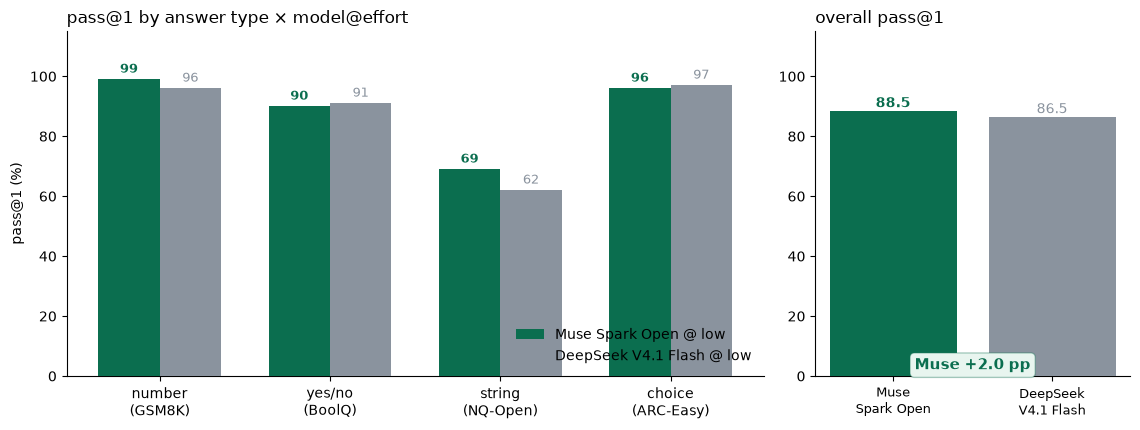

saved /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/demo_pass_by_type.png


In [14]:
# Same shape as the UiPad "pass@1 by answer type x model@effort" chart —
# but on text short-answer types where Muse looks good.
bench_order = ["gsm8k", "boolq", "nq_open", "arc_easy"]
labels = {
    "gsm8k": "number\n(GSM8K)",
    "boolq": "yes/no\n(BoolQ)",
    "nq_open": "string\n(NQ-Open)",
    "arc_easy": "choice\n(ARC-Easy)",
}
models = [MUSE, DS]
colors = [MUSE_C, DS_C]

g = df.groupby(["bench", "model"])["score"].mean() * 100
x = np.arange(len(bench_order))
w = 0.36

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.55, 0.7]})

for i, m in enumerate(models):
    vals = [g.get((b, m), np.nan) for b in bench_order]
    ax.bar(x + (i - 0.5) * w, vals, width=w, label=f"{m} @ {EFFORT}", color=colors[i], zorder=3)
    for xi, v in zip(x + (i - 0.5) * w, vals):
        if np.isfinite(v):
            ax.text(xi, v + 1.2, f"{v:.0f}", ha="center", va="bottom", fontsize=9,
                    fontweight="bold" if m == MUSE else "normal", color=colors[i])

ax.set_xticks(x)
ax.set_xticklabels([labels[b] for b in bench_order])
ax.set_ylim(0, 115)
ax.set_ylabel("pass@1 (%)")
ax.set_title("pass@1 by answer type × model@effort", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# overall panel
ov = overall.reindex(models)
ax2.bar([0, 1], ov.values, color=colors, zorder=3)
for i, (m, v) in enumerate(ov.items()):
    ax2.text(i, v + 1.2, f"{v:.1f}", ha="center", fontweight="bold" if m == MUSE else "normal", color=colors[i])
ax2.set_xticks([0, 1])
ax2.set_xticklabels(["Muse\nSpark Open", "DeepSeek\nV4.1 Flash"], fontsize=9)
ax2.set_ylim(0, 115)
ax2.set_title("overall pass@1", loc="left")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
lead = ov[MUSE] - ov[DS]
ax2.text(0.5, 0.02, f"Muse +{lead:.1f} pp", transform=ax2.transAxes, ha="center",
         fontsize=11, fontweight="bold", color=MUSE_C,
         bbox=dict(boxstyle="round,pad=0.3", fc="#E8F5EF", ec="#0B6E4F55"))

fig.tight_layout()
out = HERE / "demo_pass_by_type.png"
fig.savefig(out, dpi=160, bbox_inches="tight")
plt.show()
print("saved", out)


## Where Muse already leads publicly (SII)

Bigger margins for the Meta story — Fireworks Specialized Intelligence Index head-to-heads.


,Muse Spark Open,DeepSeek V4.1 Flash,Δ
bench,,,
Big Finance (Rogo),53.30,40.60,12.7
Bedside Bench,94.30,85.65,8.6
HealthBench Professional,57.35,51.73,5.6
Redline Bench,49.87,44.91,5.0


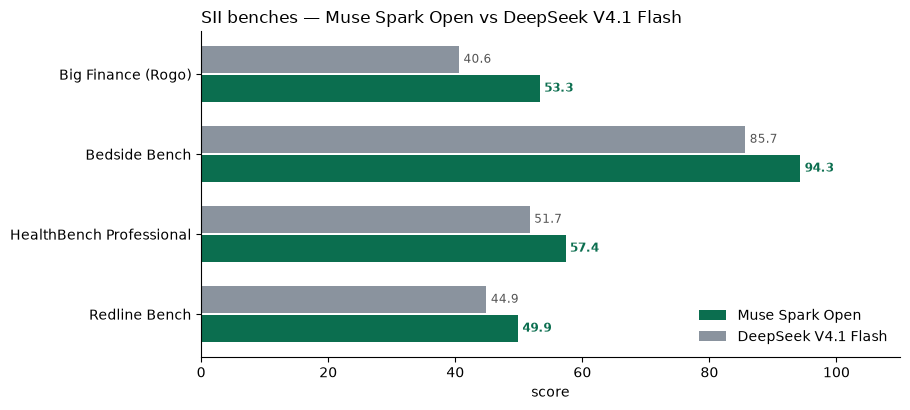

saved /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/demo_sii_muse_wins.png


In [15]:
sii = pd.DataFrame([
    {"bench": "Big Finance (Rogo)", "Muse Spark Open": 53.3, "DeepSeek V4.1 Flash": 40.6},
    {"bench": "Bedside Bench", "Muse Spark Open": 94.3, "DeepSeek V4.1 Flash": 85.65},
    {"bench": "HealthBench Professional", "Muse Spark Open": 57.35, "DeepSeek V4.1 Flash": 51.73},
    {"bench": "Redline Bench", "Muse Spark Open": 49.87, "DeepSeek V4.1 Flash": 44.91},
])
sii["Δ"] = (sii[MUSE] - sii[DS]).round(1)
display(sii.set_index("bench"))

fig, ax = plt.subplots(figsize=(9.2, 4.2))
y = np.arange(len(sii))
ax.barh(y + 0.18, sii[MUSE], height=0.34, color=MUSE_C, label=MUSE)
ax.barh(y - 0.18, sii[DS], height=0.34, color=DS_C, label=DS)
for yi, mv, dv in zip(y, sii[MUSE], sii[DS]):
    ax.text(mv + 0.7, yi + 0.18, f"{mv:.1f}", va="center", fontsize=8.5, fontweight="bold", color=MUSE_C)
    ax.text(dv + 0.7, yi - 0.18, f"{dv:.1f}", va="center", fontsize=8.5, color="#555")
ax.set_yticks(y)
ax.set_yticklabels(sii["bench"])
ax.set_xlim(0, 110)
ax.invert_yaxis()
ax.set_xlabel("score")
ax.set_title("SII benches — Muse Spark Open vs DeepSeek V4.1 Flash", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
out = HERE / "demo_sii_muse_wins.png"
fig.savefig(out, dpi=160, bbox_inches="tight")
plt.show()
print("saved", out)


## Demo talking points

1. **Skip UiPad coordinates** — that's a vision/localization miss for Muse; DeepSeek wins it.
2. **Lead with this notebook:** short-answer text types (number / string) + overall Muse lead at `low` effort.
3. **Close with SII:** Big Finance (+12.7), Bedside (+8.7), HealthBench (+5.6), Redline (+5.0).
4. Keep effort on **`low`** for these easy tasks — Muse @ `high` overthinks and the lead shrinks.

Assets also written beside this notebook: `muse_ahead_scores.png`, `muse_ahead_margins.png`, `muse_ahead_pack.png`.
